# NaiveBayes
## 1. Import libraries and necessary files, data

In [17]:
import sys
from pathlib import Path
import numpy as np

# Lấy thư mục gốc của project (thư mục cha của thư mục notebooks hiện tại)
project_dir = Path.cwd().parent

# Thêm thư mục gốc vào sys.path để Python nhận diện các module
sys.path.insert(0, str(project_dir))

# Import các module và dữ liệu

from NaiveBayes import NaiveBayes, gaussian_log_pdf
from data.preprocessing import (
    X_train_scaled,
    X_val_scaled,
    X_test_scaled,
    y_train,
    y_val,
    y_test,
)

## 2. Train Model and Classification report
### 2.1 Gaussian_log_pdf

In [18]:
from sklearn.metrics import classification_report
nb_model = NaiveBayes(log_pdf = gaussian_log_pdf)

nb_model.fit(X_train_scaled, y_train)
y_pred = nb_model.predict(X_test_scaled)
print("Đã huấn luyện mô hình Naive Bayes thành công!")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names= nb_model.classes.astype(str)))

Đã huấn luyện mô hình Naive Bayes thành công!
Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.87      0.83       980
           1       0.84      0.96      0.89      1135
           2       0.91      0.25      0.40      1032
           3       0.70      0.35      0.47      1010
           4       0.90      0.21      0.34       982
           5       0.55      0.05      0.09       892
           6       0.62      0.94      0.74       958
           7       0.88      0.27      0.41      1028
           8       0.28      0.59      0.38       974
           9       0.35      0.95      0.52      1009

    accuracy                           0.55     10000
   macro avg       0.68      0.54      0.51     10000
weighted avg       0.69      0.55      0.51     10000



#### 2.1.1 PCA giảm chiều dữ liệu 

Số chiều:  10 | Accuracy: 76.33%
Số chiều:  30 | Accuracy: 85.69%
Số chiều:  50 | Accuracy: 87.09%
Số chiều: 100 | Accuracy: 86.96%
Số chiều: 150 | Accuracy: 85.65%
Số chiều: 200 | Accuracy: 84.70%
Số chiều: 300 | Accuracy: 81.96%


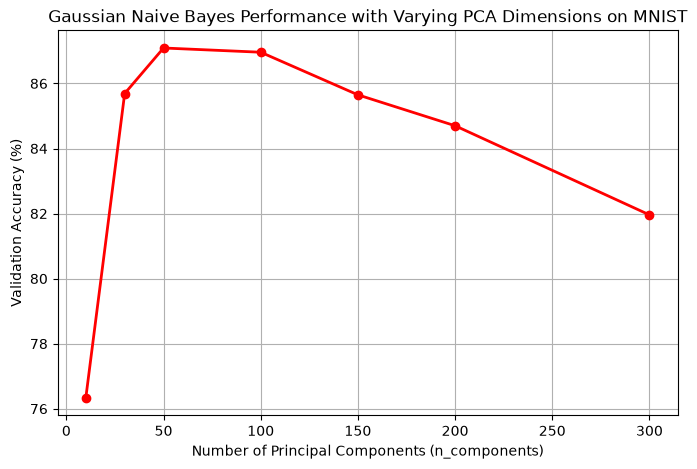

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

# Danh sách các mốc số chiều (n_components) cần thử nghiệm
n_components_list = [10, 30, 50, 100, 150, 200, 300]
accuracies = []

for n_comp in n_components_list:
    # 1. Khởi tạo và fit PCA trên tập train
    pca = PCA(n_components=n_comp)
    X_train_pca = pca.fit_transform(X_train_scaled)  # Giảm chiều dữ liệu train
    X_val_pca = pca.transform(X_val_scaled)  # Chiếu tập val lên cùng không gian PCA

    # 2. Huấn luyện Gaussian Naive Bayes trên dữ liệu đã giảm chiều
    model = NaiveBayes(log_pdf=gaussian_log_pdf)
    model.fit(X_train_pca, y_train)

    # 3. Dự đoán và tính độ chính xác
    y_pred = model.predict(X_val_pca)
    acc = accuracy_score(y_val, y_pred)
    accuracies.append(acc)
    print(f"Số chiều: {n_comp:3d} | Accuracy: {acc * 100:.2f}%")

# 4. Vẽ biểu đồ phân tích cho báo cáo
plt.figure(figsize=(8, 5))
plt.plot(
    n_components_list,
    [a * 100 for a in accuracies],
    marker='o',
    color='r',
    linestyle='-',
    linewidth=2,
)
plt.title(
    'Gaussian Naive Bayes Performance with Varying PCA Dimensions on MNIST'
)
plt.xlabel('Number of Principal Components (n_components)')
plt.ylabel('Validation Accuracy (%)')
plt.grid(True)
plt.show()

## 3. Logistic_Regression


In [19]:
if __name__ == "__main__":
    "==============Logistic Regression==============="
    #Create the model.
    model: LogisticRegression = LogisticRegression(
        learning_rate = 0.1,
        n_epochs = 30,
        batch_size = 256,
        reg_strength = 0.0001,
        random_state = 42,
    )
    #Training using the training subset.
    model.fit(X_train_scaled, y_train)

    #Evaluate using the validation subset.
    validation_accuracy: float = model.score(X_val_scaled, y_val)

    #Display validation accuracy.
    print(f"Validation accuracy: {validation_accuracy: .2%}")


Epoch 001/030 | Training loss:  0.493745
Epoch 002/030 | Training loss:  0.415636
Epoch 003/030 | Training loss:  0.382344
Epoch 004/030 | Training loss:  0.364118
Epoch 005/030 | Training loss:  0.350802
Epoch 006/030 | Training loss:  0.340709
Epoch 007/030 | Training loss:  0.333437
Epoch 008/030 | Training loss:  0.327545
Epoch 009/030 | Training loss:  0.322504
Epoch 010/030 | Training loss:  0.317848
Epoch 011/030 | Training loss:  0.314505
Epoch 012/030 | Training loss:  0.312388
Epoch 013/030 | Training loss:  0.308500
Epoch 014/030 | Training loss:  0.305709
Epoch 015/030 | Training loss:  0.304015
Epoch 016/030 | Training loss:  0.302093
Epoch 017/030 | Training loss:  0.300175
Epoch 018/030 | Training loss:  0.298125
Epoch 019/030 | Training loss:  0.296865
Epoch 020/030 | Training loss:  0.295511
Epoch 021/030 | Training loss:  0.294452
Epoch 022/030 | Training loss:  0.293076
Epoch 023/030 | Training loss:  0.291316
Epoch 024/030 | Training loss:  0.290452
Epoch 025/030 | 